<a href="https://colab.research.google.com/github/Mufliha-Hafsyah/Machine-Learning/blob/main/Week06Regresi/TugasPraktikum.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# **PRAKTIKUM PEMBELAJARAN MESIN**

**Nama**  : Mufliha Hafsyah Shahieza <br>
**NIM**   : 244107020147 <br>
**Kelas** : TI-3G

---

# **JS06 - Regresi**<hr>
# **Tugas Praktikum: Multiple Linear Regression dengan Dataset Medical Cost Personal Datasets**

1. Identifikasi variabel-variabel yang akan digunakan sebagai variabel bebas (fitur) dan variabel target (biaya medis personal).

2. Bagi dataset menjadi data latih (train) dan data uji (test) dengan proporsi yang sesuai.

3. Lakukan feature scaling jika diperlukan.

4. Buat model multiple linear regression menggunakan Scikit-Learn.

5. Latih model pada data latih dan lakukan prediksi pada data uji.

6. Evaluasi model dengan menghitung metrik seperti R-squared, MSE, dan MAE. Tampilkan hasil evaluasi.<hr>

## **Deskripsi Dataset**
Dataset Medical Cost Personal terdiri dari 1338 baris dan 7 kolom, tanpa missing value.

| Variabel | Tipe | Keterangan |
|---|---|---|
| age | numerik | Usia (tahun) |
| sex | kategorikal | Jenis kelamin |
| bmi | numerik | Indeks massa tubuh |
| children | numerik | Jumlah anak/tanggungan |
| smoker | kategorikal | Perokok atau tidak |
| region | kategorikal | Wilayah tempat tinggal |
| charges | numerik | **Target**: biaya medis |

## **Langkah 1: Muat dataset**

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

df = pd.read_csv('insurance.csv')  # sesuaikan dengan nama file yang kamu download

print(df.head())
print(df.info())
print(df.describe())
print(df.isnull().sum())

   age     sex     bmi  children smoker     region      charges
0   19  female  27.900         0    yes  southwest  16884.92400
1   18    male  33.770         1     no  southeast   1725.55230
2   28    male  33.000         3     no  southeast   4449.46200
3   33    male  22.705         0     no  northwest  21984.47061
4   32    male  28.880         0     no  northwest   3866.85520
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 1338 entries, 0 to 1337
Data columns (total 7 columns):
 #   Column    Non-Null Count  Dtype  
---  ------    --------------  -----  
 0   age       1338 non-null   int64  
 1   sex       1338 non-null   object 
 2   bmi       1338 non-null   float64
 3   children  1338 non-null   int64  
 4   smoker    1338 non-null   object 
 5   region    1338 non-null   object 
 6   charges   1338 non-null   float64
dtypes: float64(2), int64(2), object(3)
memory usage: 73.3+ KB
None
               age          bmi     children       charges
count  1338.000000  1338.000000 

## **Langkah 2: Tentukan variabel**

In [2]:
for kol in ['sex', 'smoker', 'region']:
    print(kol, df[kol].unique())

sex ['female' 'male']
smoker ['yes' 'no']
region ['southwest' 'southeast' 'northwest' 'northeast']


## **Langkah 3: Encoding dan split data**

In [3]:
# Encoding variabel kategorikal
df_enc = pd.get_dummies(df, columns=['sex', 'smoker', 'region'], drop_first=True)
print(df_enc.head())

# Pisahkan fitur dan target
X = df_enc.drop('charges', axis=1)
y = df_enc['charges']

# Bagi data latih dan uji (80:20)
from sklearn.model_selection import train_test_split
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42)

print(X_train.shape, X_test.shape)

   age     bmi  children      charges  sex_male  smoker_yes  region_northwest  \
0   19  27.900         0  16884.92400     False        True             False   
1   18  33.770         1   1725.55230      True       False             False   
2   28  33.000         3   4449.46200      True       False             False   
3   33  22.705         0  21984.47061      True       False              True   
4   32  28.880         0   3866.85520      True       False              True   

   region_southeast  region_southwest  
0             False              True  
1              True             False  
2              True             False  
3             False             False  
4             False             False  
(1070, 8) (268, 8)


## **Langkah 4: Latih model dan prediksi**

In [4]:
from sklearn.linear_model import LinearRegression

model = LinearRegression()
model.fit(X_train, y_train)

y_pred = model.predict(X_test)

# Koefisien model (berguna untuk analisis)
koef = pd.DataFrame({'Fitur': X.columns, 'Koefisien': model.coef_})
print(koef)
print("Intercept:", model.intercept_)

              Fitur     Koefisien
0               age    256.975706
1               bmi    337.092552
2          children    425.278784
3          sex_male    -18.591692
4        smoker_yes  23651.128856
5  region_northwest   -370.677326
6  region_southeast   -657.864297
7  region_southwest   -809.799354
Intercept: -11931.21905032666


## **Langkah 5: Evaluasi model**

In [5]:
from sklearn.metrics import r2_score, mean_squared_error, mean_absolute_error

r2 = r2_score(y_test, y_pred)
mse = mean_squared_error(y_test, y_pred)
rmse = np.sqrt(mse)
mae = mean_absolute_error(y_test, y_pred)

print("R-squared:", r2)
print("MSE:", mse)
print("RMSE:", rmse)
print("MAE:", mae)

# Pembanding: R-squared pada data latih
print("R-squared (train):", model.score(X_train, y_train))

R-squared: 0.7835929767120724
MSE: 33596915.85136145
RMSE: 5796.284659276273
MAE: 4181.19447375365
R-squared (train): 0.7417255854683333


## **Langkah 6: Visualisasi**

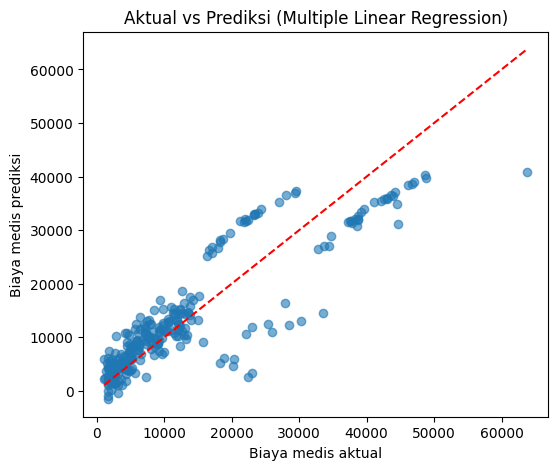

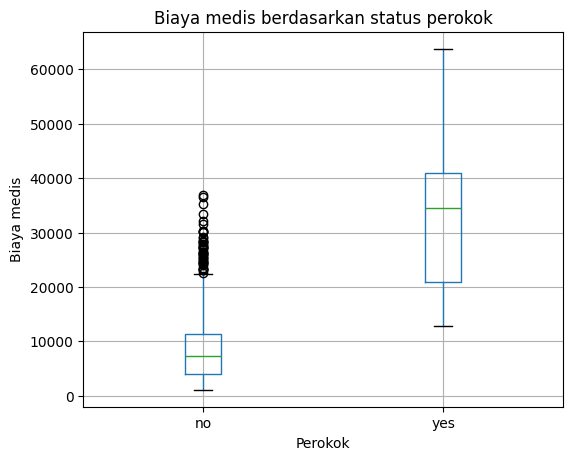

In [6]:
# 1. Aktual vs prediksi
plt.figure(figsize=(6,5))
plt.scatter(y_test, y_pred, alpha=0.6)
plt.plot([y_test.min(), y_test.max()], [y_test.min(), y_test.max()], 'r--')
plt.xlabel('Biaya medis aktual')
plt.ylabel('Biaya medis prediksi')
plt.title('Aktual vs Prediksi (Multiple Linear Regression)')
plt.show()

# 2. Biaya medis berdasarkan status perokok
df.boxplot(column='charges', by='smoker', figsize=(6,5))
plt.title('Biaya medis berdasarkan status perokok')
plt.suptitle('')
plt.xlabel('Perokok')
plt.ylabel('Biaya medis')
plt.show()

Pada grafik aktual vs prediksi, sebagian besar titik pada biaya rendah berada dekat garis diagonal, namun terdapat kelompok titik yang menyimpang: biaya aktual sekitar 20.000-35.000 diprediksi jauh lebih rendah, serta beberapa prediksi bernilai negatif. Hal ini menunjukkan keterbatasan model linear dalam menangkap hubungan yang kompleks, kemungkinan akibat adanya interaksi antarvariabel. Boxplot menunjukkan bahwa median biaya medis perokok (±34.500) jauh lebih tinggi daripada bukan perokok (±7.500), sejalan dengan koefisien smoker_yes yang paling dominan pada model.

## **Analisis:**
Model multiple linear regression menghasilkan R² sebesar 0,784 pada data uji, MAE 4.181, MSE 33.596.916, dan RMSE 5.796. R² data latih (0,742) tidak jauh berbeda dengan data uji sehingga model tidak menunjukkan overfitting. Berdasarkan koefisien, status perokok (smoker_yes) merupakan faktor dengan pengaruh terbesar terhadap biaya medis (+23.651), diikuti oleh jumlah anak, BMI, dan usia. Jenis kelamin hampir tidak berpengaruh. Koefisien wilayah bernilai negatif relatif terhadap wilayah northeast. Namun, nilai MAE yang setara sekitar 31% dari rata-rata biaya dan RMSE yang lebih besar dari MAE menunjukkan masih ada prediksi dengan galat besar, kemungkinan karena distribusi biaya yang miring dan hubungan antarvariabel yang tidak sepenuhnya linear.

## **Kesimpulan:**
Model multiple linear regression mencapai R² 0,784 pada data uji dengan MAE 4.181, dan tidak menunjukkan overfitting. Status perokok merupakan faktor yang paling berpengaruh terhadap biaya medis. Keterbatasan model terlihat dari prediksi negatif dan kelompok data yang menyimpang, sehingga pengembangan berikutnya dapat mencoba interaksi antarfitur atau model non-linear.